# Regression and Classification with Scikit-learn

**Task:** train at least two machine learning models, then compare them with proper evaluation metrics.

I went a bit past the minimum. For every algorithm I could, I did it **twice**:

1. **From scratch** with plain NumPy. This is the code from my *Machine-Learning-From-Scratch* repo (Linear Regression, Logistic Regression, KNN, Decision Tree, Naive Bayes), lightly adapted so it runs on the datasets below.
2. **With scikit-learn**, so I can check that my hand-written versions actually behave like the real thing.

Random Forest wasn't in my scratch repo yet, so that one is scikit-learn only.

| Part | Problem | Dataset | Models |
|---|---|---|---|
| 1 | Regression | Diabetes (442 patients, 10 features) | Linear Regression, Decision Tree, Random Forest, KNN |
| 2 | Classification | Breast Cancer Wisconsin (569 tumours, 30 features) | Logistic Regression, Decision Tree, Random Forest, KNN, Naive Bayes |

Both datasets ship inside scikit-learn, so nothing needs downloading.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

# classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# metrics
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

---
# Part 1: Regression

## 1.1 The data

The diabetes dataset has 442 patients. Each row has 10 baseline measurements (age, sex, BMI, blood pressure and six blood serum values), and the target is a number measuring how far the disease had progressed one year later. We're trying to predict that number.

In [2]:
diabetes = load_diabetes(as_frame=True)
X_reg, y_reg = diabetes.data, diabetes.target

print("shape:", X_reg.shape)
print("missing values:", int(X_reg.isna().sum().sum()))
X_reg.head()

shape: (442, 10)
missing values: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


count    442.0
mean     152.1
std       77.1
min       25.0
25%       87.0
50%      140.5
75%      211.5
max      346.0
Name: target, dtype: float64


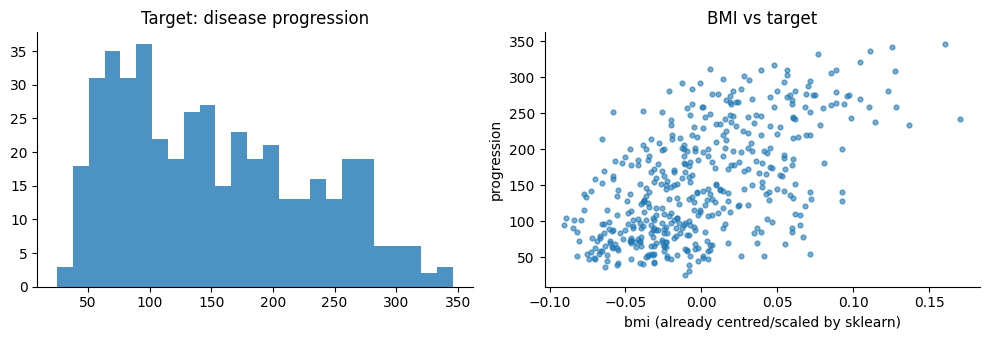

In [3]:
print(y_reg.describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(y_reg, bins=25, color="tab:blue", alpha=0.8)
ax[0].set_title("Target: disease progression")
ax[1].scatter(X_reg["bmi"], y_reg, s=12, alpha=0.6)
ax[1].set_xlabel("bmi (already centred/scaled by sklearn)")
ax[1].set_ylabel("progression")
ax[1].set_title("BMI vs target")
plt.tight_layout(); plt.show()

No missing values, and BMI has a clear upward trend with the target, which is a good sign for a linear model. I'll hold out 20% for testing and keep that split the same for every model so the comparison is fair.

Linear Regression (gradient descent) and KNN care about feature scale, trees don't. I'll standardise using **only the training set's** mean and std, then apply that to the test set so nothing leaks.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

print("train:", X_train.shape, " test:", X_test.shape)

train: (353, 10)  test: (89, 10)


## 1.2 Linear Regression from scratch (my repo version)

Same idea as my `Linear_Regression.ipynb`: define a cost function (mean squared error / 2), its gradient, and run gradient descent on `w` and `b`.

Two changes from the original notebook:
- it handles **many features** now (the original had one feature, `YearsExperience`), so `w` is a vector
- the maths is **vectorised**. The loop version works fine for one feature but gets painfully slow with ten

I also store the cost at every step so I can check that it's really converging.

In [5]:
class LinearRegressionScratch:
    def __init__(self, alpha=0.1, iterations=5000):
        self.alpha = alpha
        self.iterations = iterations

    def cost_function(self, X, y, w, b):
        m = len(y)
        errors = X @ w + b - y
        return (1 / (2 * m)) * np.sum(errors ** 2)

    def gradient_function(self, X, y, w, b):
        m = len(y)
        errors = X @ w + b - y
        dc_dw = (1 / m) * (X.T @ errors)
        dc_db = (1 / m) * np.sum(errors)
        return dc_dw, dc_db

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.cost_history = []

        for i in range(self.iterations):
            dc_dw, dc_db = self.gradient_function(X, y, self.w, self.b)
            self.w = self.w - self.alpha * dc_dw
            self.b = self.b - self.alpha * dc_db
            self.cost_history.append(self.cost_function(X, y, self.w, self.b))
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

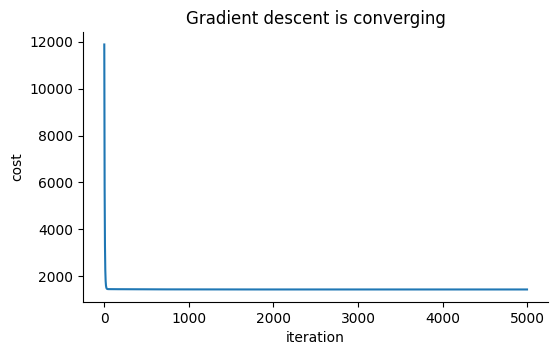

final cost: 1434.28
bias b    : 153.74 (should be close to mean of y_train = 153.74 )


In [6]:
lin_scratch = LinearRegressionScratch(alpha=0.1, iterations=5000).fit(X_train_s, y_train)

plt.figure(figsize=(6, 3.5))
plt.plot(lin_scratch.cost_history)
plt.xlabel("iteration"); plt.ylabel("cost"); plt.title("Gradient descent is converging")
plt.show()

print("final cost:", round(lin_scratch.cost_history[-1], 2))
print("bias b    :", round(lin_scratch.b, 2), "(should be close to mean of y_train =", round(y_train.mean(), 2), ")")

The cost drops fast and flattens out, so the learning rate of 0.1 works with standardised features. Quick visual sanity check using only BMI (one feature, like my original notebook) so I can draw the line:

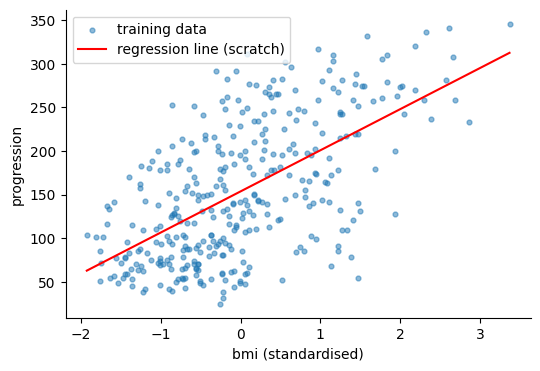

In [7]:
bmi_scaled = X_train_s[:, list(X_reg.columns).index("bmi")].reshape(-1, 1)

one_feature = LinearRegressionScratch(alpha=0.1, iterations=3000).fit(bmi_scaled, y_train)

xs = np.linspace(bmi_scaled.min(), bmi_scaled.max(), 100).reshape(-1, 1)
plt.figure(figsize=(6, 4))
plt.scatter(bmi_scaled, y_train, s=12, alpha=0.5, label="training data")
plt.plot(xs, one_feature.predict(xs), color="red", label="regression line (scratch)")
plt.xlabel("bmi (standardised)"); plt.ylabel("progression"); plt.legend(); plt.show()

## 1.3 Linear Regression with scikit-learn

Same model, one line. If my gradient descent is right, the coefficients should be almost identical (sklearn solves it exactly with least squares instead of iterating).

In [8]:
lin_sk = LinearRegression().fit(X_train_s, y_train)

coef_compare = pd.DataFrame({
    "feature": X_reg.columns,
    "scratch w": lin_scratch.w.round(3),
    "sklearn coef": lin_sk.coef_.round(3),
})
coef_compare.loc[len(coef_compare)] = ["(intercept)", round(lin_scratch.b, 3), round(lin_sk.intercept_, 3)]
coef_compare

,feature,scratch w,sklearn coef
0,age,1.756,1.754
1,sex,-11.511,-11.512
2,bmi,25.615,25.607
3,bp,16.826,16.829
4,s1,-44.039,-44.449
5,s2,24.320,24.641
6,s3,7.496,7.677
7,s4,13.082,13.139
8,s5,35.004,35.161
9,s6,2.354,2.351


They agree to about one decimal place. The tiny leftover gap is just gradient descent stopping a hair before the exact answer. So the from-scratch version is doing the real thing.

## 1.4 The other regressors (scikit-learn)

Decision Tree, Random Forest and KNN for regression. I limited the tree depth to 4 because an unrestricted tree just memorises the training set. For KNN I used k=10, which is a middle-of-the-road choice on a dataset this small.

In [9]:
reg_models = {
    "Linear Regression (scratch)": None,  # already trained above
    "Linear Regression (sklearn)": lin_sk,
    "Decision Tree (sklearn)": DecisionTreeRegressor(max_depth=4, random_state=SEED),
    "Random Forest (sklearn)": RandomForestRegressor(n_estimators=200, max_depth=6, random_state=SEED),
    "KNN (sklearn, k=10)": KNeighborsRegressor(n_neighbors=10),
}

# trees/forest don't need scaling, but using the scaled data for everything keeps the code simple
for name, model in reg_models.items():
    if model is not None and name != "Linear Regression (sklearn)":
        model.fit(X_train_s, y_train)

reg_models["Linear Regression (scratch)"] = lin_scratch
print("all regression models trained")

all regression models trained


## 1.5 Evaluating the regression models

Four metrics on the held-out test set:
- **MAE**: average size of the miss, in the target's own units
- **MSE**: average squared miss (punishes big misses harder)
- **RMSE**: square root of MSE, back in the target's units
- **R²**: share of the variance the model explains (1 is perfect, 0 is no better than always guessing the mean)

In [10]:
def regression_row(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2": r2_score(y_true, y_pred)}

reg_results = pd.DataFrame([
    regression_row(name, y_test, model.predict(X_test_s)) for name, model in reg_models.items()
]).sort_values("R2", ascending=False).reset_index(drop=True)

reg_results.round(3)

,Model,MAE,MSE,RMSE,R2
0,Random Forest (sklearn),43.640,2894.460,53.800,0.454
1,Linear Regression (scratch),42.795,2899.856,53.850,0.453
2,Linear Regression (sklearn),42.794,2900.194,53.853,0.453
3,"KNN (sklearn, k=10)",45.111,3168.353,56.288,0.402
4,Decision Tree (sklearn),47.045,3568.965,59.741,0.326


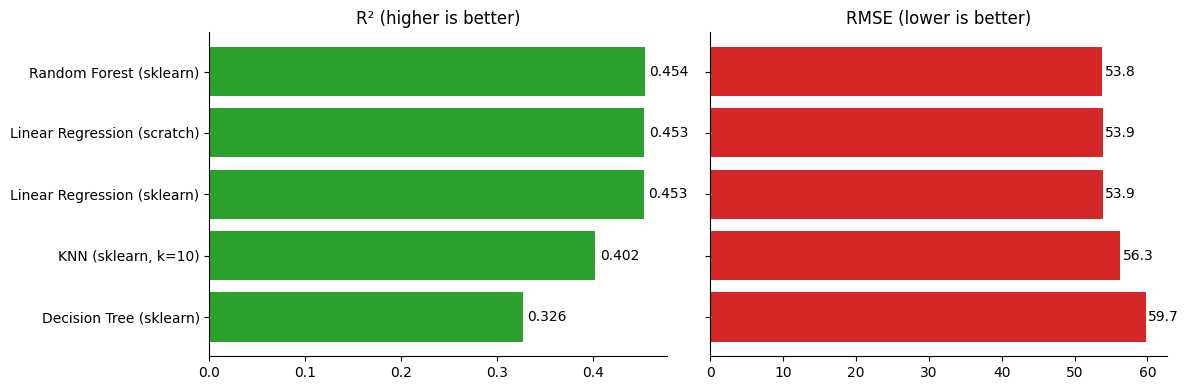

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = reg_results["Model"]

ax[0].barh(order, reg_results["R2"], color="tab:green")
ax[0].invert_yaxis(); ax[0].set_title("R² (higher is better)")
for i, v in enumerate(reg_results["R2"]): ax[0].text(v + 0.005, i, f"{v:.3f}", va="center")

ax[1].barh(order, reg_results["RMSE"], color="tab:red")
ax[1].invert_yaxis(); ax[1].set_title("RMSE (lower is better)")
for i, v in enumerate(reg_results["RMSE"]): ax[1].text(v + 0.3, i, f"{v:.1f}", va="center")
ax[1].set_yticklabels([])

plt.tight_layout(); plt.show()

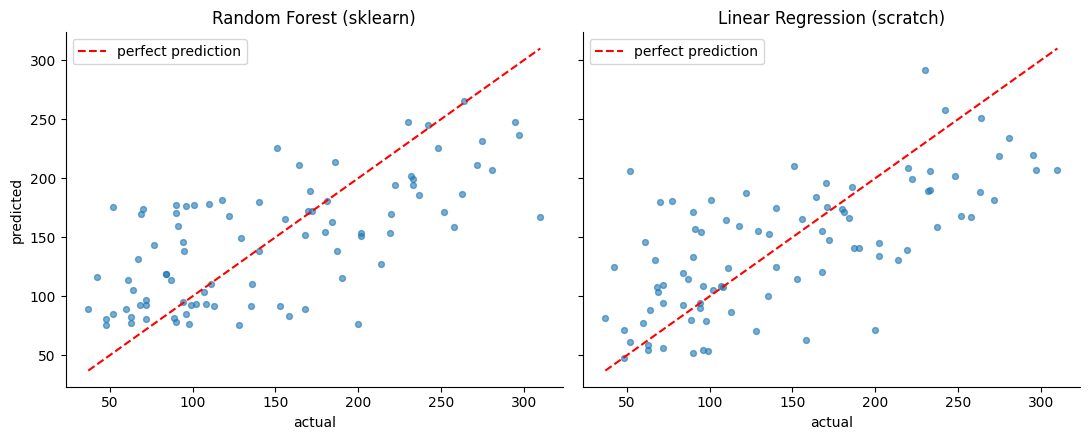

In [12]:
# predicted vs actual for the best two models
best_two = reg_results["Model"].head(2).tolist()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, name in zip(ax, best_two):
    pred = reg_models[name].predict(X_test_s)
    a.scatter(y_test, pred, alpha=0.6, s=18)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    a.plot(lims, lims, "r--", label="perfect prediction")
    a.set_title(name); a.set_xlabel("actual"); a.legend()
ax[0].set_ylabel("predicted")
plt.tight_layout(); plt.show()

One test split of 89 patients is a small sample, so a gap of a couple of points in R² could just be luck of the split. To check, here's 5-fold cross-validation on all 442 rows for the scikit-learn models (the scaler sits inside a pipeline, so each fold scales using only its own training part).

In [13]:
sk_reg = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree":     make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=4, random_state=SEED)),
    "Random Forest":     make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=200, max_depth=6, random_state=SEED)),
    "KNN (k=10)":        make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
}

cv_rows = []
for name, pipe in sk_reg.items():
    scores = cross_val_score(pipe, X_reg, y_reg, cv=5, scoring="r2")
    cv_rows.append({"Model": name, "CV R2 (mean)": scores.mean(), "CV R2 (std)": scores.std()})

pd.DataFrame(cv_rows).sort_values("CV R2 (mean)", ascending=False).round(3).reset_index(drop=True)

,Model,CV R2 (mean),CV R2 (std)
0,Linear Regression,0.482,0.049
1,Random Forest,0.435,0.058
2,KNN (k=10),0.429,0.057
3,Decision Tree,0.293,0.094


### What I take from Part 1

- **My scratch Linear Regression is the real deal.** R² 0.453 and MAE 42.80 against scikit-learn's 0.453 and 42.79, with coefficients matching to about one decimal. Gradient descent and the closed-form solution end up in the same place.
- **On the single test split, three models are basically tied.** Random Forest (R² 0.454, RMSE 53.8) and both Linear Regressions (R² 0.453, RMSE 53.85) are separated by differences too small to mean anything. KNN is a bit behind (0.402) and the single Decision Tree is last (0.326).
- **Cross-validation changes the story a little.** Over 5 folds, plain Linear Regression comes out on top (R² 0.482), ahead of Random Forest (0.435) and KNN (0.429), while the Decision Tree is still last (0.293) and by far the most unstable (std 0.094). So Random Forest's tiny lead on the test split looks like luck of the split, not a real advantage.
- **Why would the simple model win?** My guess is that with only 442 rows and 10 features, there isn't much non-linear structure for the flexible models to find, so they mostly add variance. I haven't tested that directly, so treat it as a hypothesis.
- **An honest caveat:** R² around 0.45 to 0.48 means roughly half the variation in disease progression is left unexplained, and an RMSE of ~54 is large against a target with a standard deviation of 77. None of these would be useful on their own for real clinical decisions. This dataset just doesn't contain much signal in its 10 baseline features.

---
# Part 2: Classification

## 2.1 The data

Breast Cancer Wisconsin: 569 tumours, 30 measurements per tumour (radius, texture, smoothness etc., each as mean / error / worst value). The job is to decide whether a tumour is **malignant** or **benign**. (This is the same dataset as the `data.csv` in my KNN and Naive Bayes notebooks.)

One thing I changed: scikit-learn labels malignant as 0 and benign as 1. For a medical problem I care most about *catching the malignant ones*, so I flipped the labels to make **malignant = 1**. That way precision and recall in the tables below are about finding cancer, not about finding healthy tumours.

In [14]:
cancer = load_breast_cancer(as_frame=True)
X_clf = cancer.data
y_clf = 1 - cancer.target          # flip: 1 = malignant, 0 = benign

print("shape:", X_clf.shape)
print("missing values:", int(X_clf.isna().sum().sum()))
print(y_clf.value_counts().rename({0: "benign", 1: "malignant"}))

shape: (569, 30)
missing values: 0
target
benign       357
malignant    212
Name: count, dtype: int64


Roughly 63% benign and 37% malignant. That's imbalanced enough that accuracy alone can fool you (a model that says "benign" every time gets ~63%), so I'll look at precision, recall and F1 too. I'm using a **stratified** split so the test set keeps the same ratio.

In [15]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf)

# scaled copies (needed for logistic regression + KNN, fit on train only)
clf_scaler = StandardScaler().fit(Xc_train)
Xc_train_s = clf_scaler.transform(Xc_train)
Xc_test_s  = clf_scaler.transform(Xc_test)

print("train:", Xc_train.shape, " test:", Xc_test.shape)
print("malignant share  train: %.1f%%   test: %.1f%%" % (yc_train.mean()*100, yc_test.mean()*100))

train: (455, 30)  test: (114, 30)
malignant share  train: 37.4%   test: 36.8%


## 2.2 The from-scratch models (copied from my repo)

These four are straight from my notebooks. Adjustments are marked with comments where I made any.

### Logistic Regression
Sigmoid + cross-entropy loss + gradient descent, as in `Logistic_Regression.ipynb`. The original used nested Python loops over every sample and every feature. With 30 features and thousands of iterations that would take ages, so I vectorised it. The maths is unchanged.

In [16]:
class LogisticRegressionScratch:
    def __init__(self, alpha=0.1, iterations=2000):
        self.alpha = alpha
        self.iterations = iterations

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def cost_function(self, X, y, w, b):
        g = self.sigmoid(X @ w + b)
        g = np.clip(g, 1e-15, 1 - 1e-15)   # added: sigmoid hits exactly 1.0 after a few hundred steps and log(0) breaks the loss curve
        return -np.mean(y * np.log(g) + (1 - y) * np.log(1 - g))

    def gradient_function(self, X, y, w, b):
        m = len(y)
        g = self.sigmoid(X @ w + b)
        grad_w = (1 / m) * (X.T @ (g - y))
        grad_b = (1 / m) * np.sum(g - y)
        return grad_b, grad_w

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.cost_history = []
        for i in range(self.iterations):
            grad_b, grad_w = self.gradient_function(X, y, self.w, self.b)
            self.w = self.w - self.alpha * grad_w
            self.b = self.b - self.alpha * grad_b
            self.cost_history.append(self.cost_function(X, y, self.w, self.b))
        return self

    def predict_proba(self, X):
        return self.sigmoid(np.asarray(X, dtype=float) @ self.w + self.b)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

### K-Nearest Neighbors
Euclidean distance to every training point, take the k closest, majority vote. Unchanged from `KNN.ipynb`.

In [17]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((b - a) ** 2))


class KNNScratch:
    def __init__(self, k):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, new_points):
        predictions = [self.predict_class(p) for p in np.asarray(new_points, dtype=float)]
        return np.array(predictions)

    def predict_class(self, new_point):
        distances = [euclidean_distance(point, new_point) for point in self.X_train]

        k_nearest_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_nearest_indices]

        most_common = Counter(k_nearest_labels).most_common(1)[0][0]
        return most_common

### Decision Tree
Entropy + information gain, recursive splitting, as in `Decision_Tree.ipynb`. I made two small changes:
- `split()` uses a boolean mask instead of looping row by row (same result, much faster on 455 rows x 30 features)
- the depth check was `curr_depth <= max_depth`, which actually allowed one level more than `max_depth`. I changed it to `<` so `max_depth=3` really means 3 levels, matching how scikit-learn counts it

In [18]:
class Node:
    def __init__(self, feature_idx=None, threshold=None, info_gain=None, left=None, right=None, value=None):
        # decision node
        self.feature_idx = feature_idx
        self.threshold = threshold
        self.info_gain = info_gain
        self.left = left
        self.right = right
        # leaf node
        self.value = value


class DecisionTreeScratch:
    def __init__(self, min_samples_split=2, max_depth=2):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth

    def build_tree(self, dataset, curr_depth=0):
        X, y = dataset[:, :-1], dataset[:, -1]
        n_samples, n_features = X.shape

        if n_samples >= self.min_samples_split and curr_depth < self.max_depth:
            best_split = self.best_split(dataset, n_features)

            if best_split["info_gain"] > 0:
                left_node = self.build_tree(best_split["left_dataset"], curr_depth + 1)
                right_node = self.build_tree(best_split["right_dataset"], curr_depth + 1)
                return Node(best_split["feature_idx"], best_split["threshold"],
                            best_split["info_gain"], left_node, right_node)

        leaf_value = Counter(y).most_common(1)[0][0]
        return Node(value=leaf_value)

    def best_split(self, dataset, n_features):
        best_split = {'feature_idx': None, 'threshold': None, 'info_gain': -1,
                      'left_dataset': None, 'right_dataset': None}

        for feature_idx in range(n_features):
            feature_values = dataset[:, feature_idx]
            thresholds = np.unique(feature_values)

            for threshold in thresholds:
                left_dataset, right_dataset = self.split(dataset, feature_idx, threshold)

                if len(left_dataset) and len(right_dataset):
                    parent_y, left_y, right_y = dataset[:, -1], left_dataset[:, -1], right_dataset[:, -1]
                    info_gain = self.information_gain(parent_y, left_y, right_y)

                    if info_gain > best_split['info_gain']:
                        best_split['feature_idx'] = feature_idx
                        best_split['threshold'] = threshold
                        best_split['info_gain'] = info_gain
                        best_split['left_dataset'] = left_dataset
                        best_split['right_dataset'] = right_dataset

        return best_split

    def split(self, dataset, feature_idx, threshold):
        mask = dataset[:, feature_idx] <= threshold      # was a row-by-row loop in the original
        return dataset[mask], dataset[~mask]

    def information_gain(self, parent_y, left_y, right_y):
        left_weight = len(left_y) / len(parent_y)
        right_weight = len(right_y) / len(parent_y)
        return self.entropy(parent_y) - (left_weight * self.entropy(left_y) + right_weight * self.entropy(right_y))

    def entropy(self, y):
        entropy = 0
        for class_label in np.unique(y):
            p = len(y[y == class_label]) / len(y)
            entropy += -p * np.log2(p)
        return entropy

    def fit(self, X, y):
        dataset = np.concatenate([np.asarray(X, dtype=float), np.asarray(y, dtype=float).reshape(-1, 1)], axis=1)
        self.root = self.build_tree(dataset)
        return self

    def predict(self, X):
        return np.array([self.predict_class(row, self.root) for row in np.asarray(X, dtype=float)]).astype(int)

    def predict_class(self, row, node):
        if node.value is not None:
            return node.value
        if row[node.feature_idx] <= node.threshold:
            return self.predict_class(row, node.left)
        return self.predict_class(row, node.right)

    def print_tree(self, feature_names=None, node=None, depth=0, indent="|   "):
        prefix = indent * depth
        if node is None:
            node = self.root
        if node.value is not None:
            print(f"{prefix}|--- class: {int(node.value)}")
            return
        label = feature_names[node.feature_idx] if feature_names is not None else f"Feature {node.feature_idx}"
        print(f"{prefix}|--- {label} <= {node.threshold:.4g}")
        self.print_tree(feature_names, node.left, depth + 1, indent)
        print(f"{prefix}|--- {label} > {node.threshold:.4g}")
        self.print_tree(feature_names, node.right, depth + 1, indent)

### Gaussian Naive Bayes
Class priors times Gaussian likelihoods for each feature, pick the class with the highest posterior. Copied as-is from `Naive_Bayes.ipynb` (it works on pandas DataFrames, so I feed it those).

In [19]:
class NaiveBayesScratch:
    def fit(self, X_train, y_train):
        self.classes = np.unique(y_train)
        self.priors = [len(y_train[y_train == c]) / len(y_train) for c in self.classes]

        self.means = [X_train[y_train == c].mean() for c in self.classes]
        self.stds = [X_train[y_train == c].std() for c in self.classes]
        return self

    def compute_likelihood(self, row, class_idx):
        likelihood = 1
        for feature in row.index:
            mean = self.means[class_idx][feature]
            std = self.stds[class_idx][feature]
            likelihood *= (1 / (np.sqrt(2 * np.pi) * std)) * np.exp((-(row[feature] - mean) ** 2) / (2 * std ** 2))
        return likelihood

    def predict(self, X):
        y_pred = []
        for _, row in X.iterrows():
            posteriors = []
            for i in range(len(self.classes)):
                likelihood = self.compute_likelihood(row, i)
                posteriors.append(likelihood * self.priors[i])
            y_pred.append(self.classes[np.argmax(posteriors)])
        return np.array(y_pred)

## 2.3 Training everything

Scratch models first. Logistic Regression and KNN get the scaled data; the tree and Naive Bayes don't need scaling, so they get the raw values. Tree depth is 3 for both the scratch and sklearn trees, and the sklearn tree uses `criterion="entropy"` to match the scratch one (sklearn's default is gini).

In [20]:
import time

scratch_models = {}
timings = {}

t = time.time()
scratch_models["Logistic Regression (scratch)"] = LogisticRegressionScratch(alpha=0.1, iterations=2000).fit(Xc_train_s, yc_train)
timings["Logistic Regression (scratch)"] = time.time() - t

t = time.time()
scratch_models["KNN (scratch, k=7)"] = KNNScratch(k=7).fit(Xc_train_s, yc_train)
timings["KNN (scratch, k=7)"] = time.time() - t

t = time.time()
scratch_models["Decision Tree (scratch)"] = DecisionTreeScratch(max_depth=3).fit(Xc_train, yc_train)
timings["Decision Tree (scratch)"] = time.time() - t

t = time.time()
scratch_models["Naive Bayes (scratch)"] = NaiveBayesScratch().fit(Xc_train, yc_train)
timings["Naive Bayes (scratch)"] = time.time() - t

# which input each model expects
scratch_inputs = {
    "Logistic Regression (scratch)": Xc_test_s,
    "KNN (scratch, k=7)": Xc_test_s,
    "Decision Tree (scratch)": Xc_test.values,
    "Naive Bayes (scratch)": Xc_test,       # DataFrame
}
print("scratch models trained")

scratch models trained


In [21]:
# peek inside my hand-written tree
scratch_models["Decision Tree (scratch)"].print_tree(feature_names=list(X_clf.columns))

|--- worst perimeter <= 114.3
|   |--- worst concave points <= 0.1108
|   |   |--- area error <= 44.96
|   |   |   |--- class: 0
|   |   |--- area error > 44.96
|   |   |   |--- class: 0
|   |--- worst concave points > 0.1108
|   |   |--- worst texture <= 25.63
|   |   |   |--- class: 0
|   |   |--- worst texture > 25.63
|   |   |   |--- class: 1
|--- worst perimeter > 114.3
|   |--- mean concave points <= 0.04835
|   |   |--- worst texture <= 28.07
|   |   |   |--- class: 0
|   |   |--- worst texture > 28.07
|   |   |   |--- class: 1
|   |--- mean concave points > 0.04835
|   |   |--- class: 1


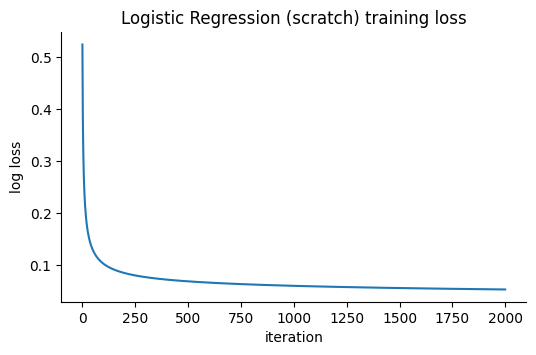

In [22]:
# and a quick look at logistic regression's loss curve
lr_s = scratch_models["Logistic Regression (scratch)"]
plt.figure(figsize=(6, 3.5))
plt.plot(lr_s.cost_history)
plt.xlabel("iteration"); plt.ylabel("log loss"); plt.title("Logistic Regression (scratch) training loss")
plt.show()

Now the scikit-learn versions, plus the Random Forest. The ones that need scaling are wrapped in a pipeline with `StandardScaler`, so I can pass raw data straight in and the scaling is learned from the training data only.

In [23]:
sk_clf = {
    "Logistic Regression (sklearn)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "KNN (sklearn, k=7)":            make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Decision Tree (sklearn)":       DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED),
    "Naive Bayes (sklearn)":         GaussianNB(),
    "Random Forest (sklearn)":       RandomForestClassifier(n_estimators=200, random_state=SEED),
}

for name, model in sk_clf.items():
    model.fit(Xc_train, yc_train)
print("sklearn models trained")

sklearn models trained


## 2.4 Evaluating the classifiers

For each model on the test set I'll report:
- **Accuracy**: share of all predictions that were right
- **Precision**: when the model says "malignant", how often is it right?
- **Recall**: of all the truly malignant tumours, how many did the model catch? (This is the one that matters most here. A missed cancer is worse than a false alarm.)
- **F1**: a single number balancing precision and recall

In [24]:
def classification_row(name, y_true, y_pred):
    return {"Model": name,
            "Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall":    recall_score(y_true, y_pred),
            "F1":        f1_score(y_true, y_pred)}

all_preds = {}
for name, model in scratch_models.items():
    all_preds[name] = np.asarray(model.predict(scratch_inputs[name])).astype(int)
for name, model in sk_clf.items():
    all_preds[name] = model.predict(Xc_test)

clf_results = pd.DataFrame([classification_row(n, yc_test, p) for n, p in all_preds.items()])
clf_results = clf_results.sort_values(["F1", "Accuracy"], ascending=False).reset_index(drop=True)
clf_results.round(4)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression (scratch),0.9737,0.9756,0.9524,0.9639
1,Logistic Regression (sklearn),0.9649,0.9750,0.9286,0.9512
2,Random Forest (sklearn),0.9649,1.0000,0.9048,0.9500
3,"KNN (scratch, k=7)",0.9561,0.9744,0.9048,0.9383
4,"KNN (sklearn, k=7)",0.9561,0.9744,0.9048,0.9383
5,Decision Tree (scratch),0.9386,0.9268,0.9048,0.9157
6,Decision Tree (sklearn),0.9386,0.9268,0.9048,0.9157
7,Naive Bayes (sklearn),0.9386,1.0000,0.8333,0.9091
8,Naive Bayes (scratch),0.9211,0.9231,0.8571,0.8889


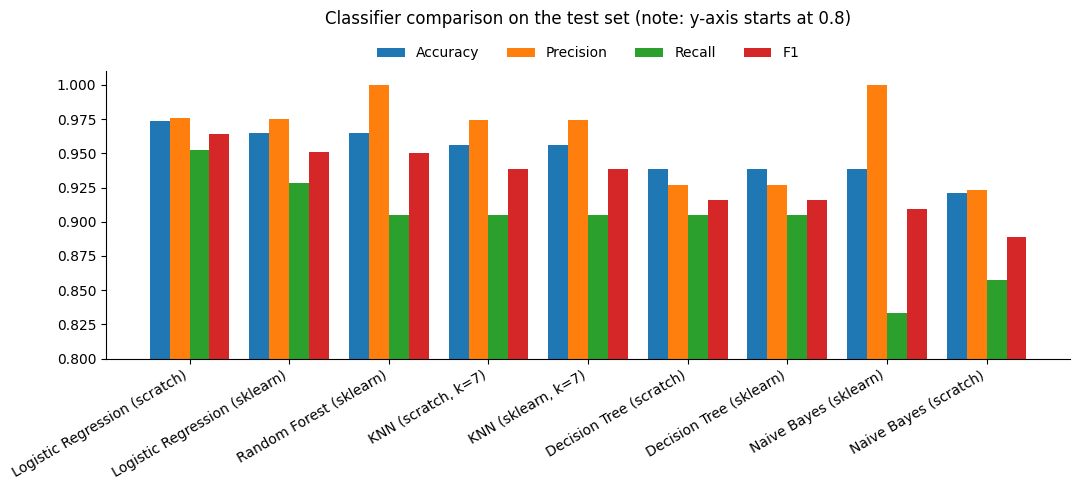

In [25]:
fig, ax = plt.subplots(figsize=(11, 5))
metrics = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(clf_results))
w = 0.2
for i, m in enumerate(metrics):
    ax.bar(x + (i - 1.5) * w, clf_results[m], w, label=m)
ax.set_xticks(x)
ax.set_xticklabels(clf_results["Model"], rotation=30, ha="right")
ax.set_ylim(0.8, 1.01)
ax.set_title("Classifier comparison on the test set (note: y-axis starts at 0.8)", pad=34)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.13), frameon=False)
plt.tight_layout(); plt.show()

Confusion matrices for all nine models. Rows are the true class, columns the predicted one. The cell I care about most is the bottom-left (a malignant tumour predicted as benign, i.e. a false negative).

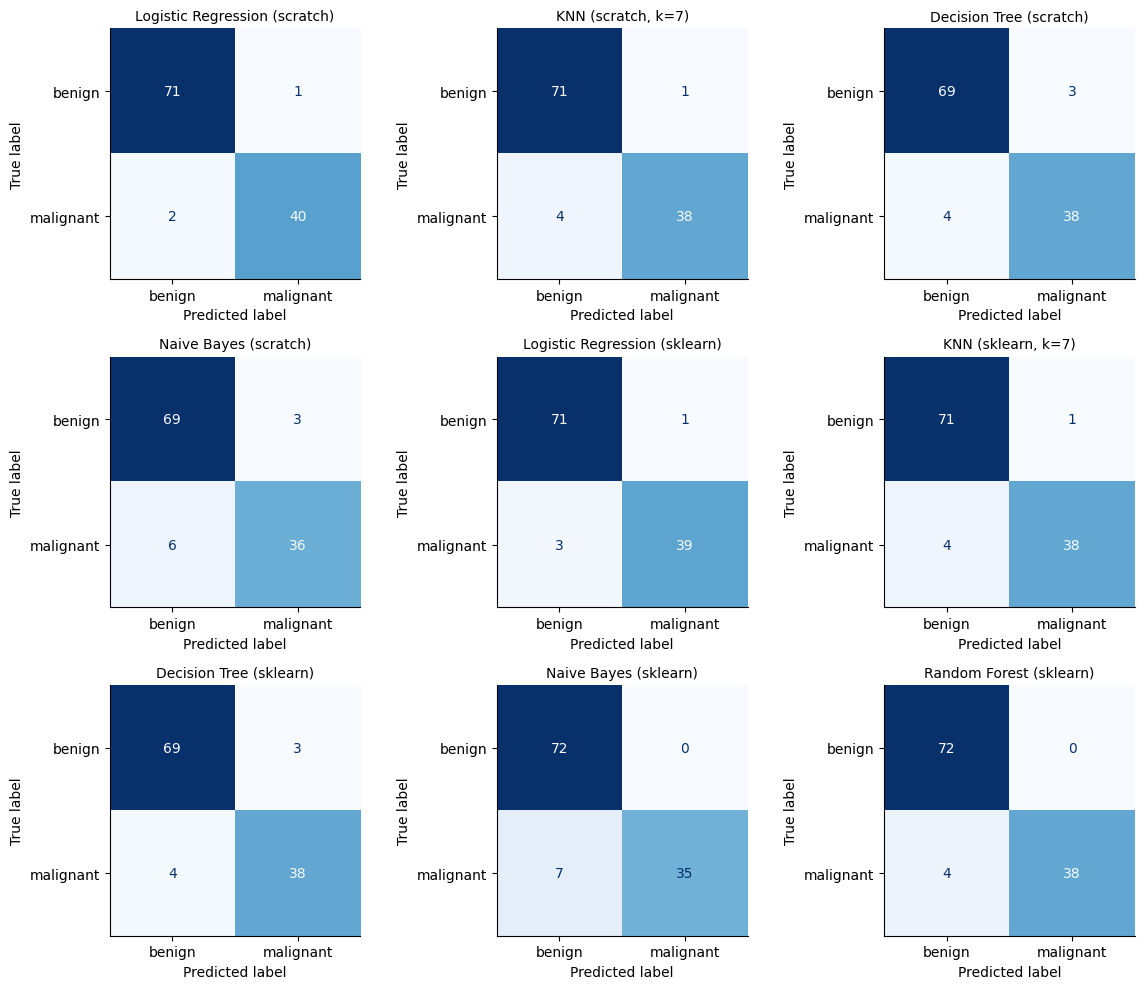

In [26]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, (name, pred) in zip(axes.ravel(), all_preds.items()):
    ConfusionMatrixDisplay.from_predictions(yc_test, pred, display_labels=["benign", "malignant"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

### Scratch vs scikit-learn, side by side
This is the check I was most curious about: does my hand-written code land in the same place as the library?

In [27]:
pairs = [("Logistic Regression (scratch)", "Logistic Regression (sklearn)"),
         ("KNN (scratch, k=7)",            "KNN (sklearn, k=7)"),
         ("Decision Tree (scratch)",       "Decision Tree (sklearn)"),
         ("Naive Bayes (scratch)",         "Naive Bayes (sklearn)")]

rows = []
for s, l in pairs:
    rows.append({"Algorithm": s.split(" (")[0],
                 "Scratch acc": accuracy_score(yc_test, all_preds[s]),
                 "sklearn acc": accuracy_score(yc_test, all_preds[l]),
                 "Scratch recall": recall_score(yc_test, all_preds[s]),
                 "sklearn recall": recall_score(yc_test, all_preds[l]),
                 "Predictions that differ": int((all_preds[s] != all_preds[l]).sum()),
                 "Scratch train time (s)": timings[s]})
pd.DataFrame(rows).round(4)

,Algorithm,Scratch acc,sklearn acc,Scratch recall,sklearn recall,Predictions that differ,Scratch train time (s)
0,Logistic Regression,0.9737,0.9649,0.9524,0.9286,1,0.0773
1,KNN,0.9561,0.9561,0.9048,0.9048,0,0.0001
2,Decision Tree,0.9386,0.9386,0.9048,0.9048,0,1.7838
3,Naive Bayes,0.9211,0.9386,0.8571,0.8333,4,0.0023


A few things stand out in that table. KNN and the Decision Tree give **exactly the same predictions** as scikit-learn (0 differences out of 114), so those two implementations are right. Logistic Regression differs on 1 prediction. Naive Bayes differs on 4, which is more than I'd expect from a correct implementation, so I dug into it.

It turns out scikit-learn's `GaussianNB` quietly adds a small number (`var_smoothing`) to every feature's variance, scaled to the largest variance in the data. My copy from the repo doesn't. In this dataset the features live on very different scales (area is in the hundreds, smoothness is around 0.01), so that padding is tiny for big features but large relative to the small ones. Let me add the same padding to my version and see if the gap closes:

In [28]:
nb_padded = NaiveBayesScratch().fit(Xc_train, yc_train)

eps = 1e-9 * Xc_train.var(ddof=0).max()                       # same formula sklearn uses
nb_padded.stds = [np.sqrt(s ** 2 + eps) for s in nb_padded.stds]

padded_pred = nb_padded.predict(Xc_test)
print("padding value        :", eps)
print("accuracy (padded)    :", round(accuracy_score(yc_test, padded_pred), 4))
print("differs from sklearn :", int((padded_pred != all_preds["Naive Bayes (sklearn)"]).sum()), "of", len(yc_test))

padding value        : 0.00033838174019611156
accuracy (padded)    : 0.9386
differs from sklearn : 0 of 114


Zero differences now. So the from-scratch Naive Bayes was never wrong, it was just missing a numerical detail that the library handles for you. I'm leaving the original version in the results table above, since that's the code from my repo.

### ROC curves (scikit-learn models)
ROC shows how well each model separates the two classes across *all* possible thresholds, not just the default 0.5. A bigger area under the curve (AUC) is better.

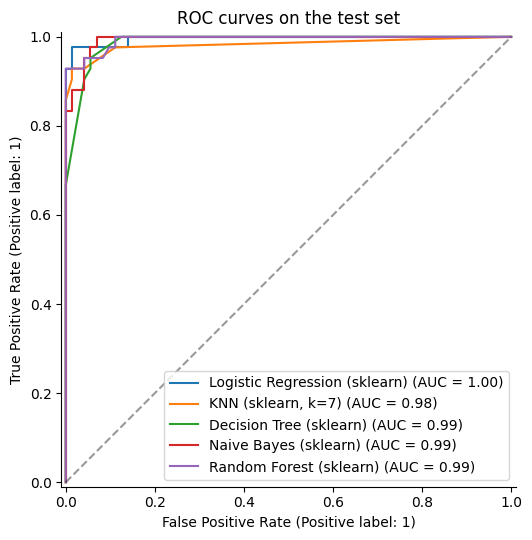

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, model in sk_clf.items():
    RocCurveDisplay.from_estimator(model, Xc_test, yc_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves on the test set")
plt.tight_layout(); plt.show()

### Is one test split enough? 5-fold cross-validation
The test set is only 114 tumours, so each mistake moves accuracy by almost 1 point. Cross-validation averages over five different splits and gives a steadier ranking (scikit-learn models only, since the scratch KNN and tree would take a while to repeat five times).

In [30]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "f1"]

cv_clf_rows = []
for name, model in sk_clf.items():
    res = cross_validate(model, X_clf, y_clf, cv=skf, scoring=scoring)
    cv_clf_rows.append({"Model": name,
                        "Accuracy": res["test_accuracy"].mean(),
                        "Acc std":  res["test_accuracy"].std(),
                        "Precision": res["test_precision"].mean(),
                        "Recall":    res["test_recall"].mean(),
                        "F1":        res["test_f1"].mean()})

cv_clf = pd.DataFrame(cv_clf_rows).sort_values("F1", ascending=False).reset_index(drop=True)
cv_clf.round(4)

,Model,Accuracy,Acc std,Precision,Recall,F1
0,Logistic Regression (sklearn),0.9737,0.0166,0.9863,0.9436,0.9633
1,"KNN (sklearn, k=7)",0.9649,0.0184,0.9856,0.9200,0.9505
2,Random Forest (sklearn),0.9543,0.0102,0.9463,0.9341,0.9382
3,Naive Bayes (sklearn),0.9385,0.0235,0.9488,0.8868,0.9143
4,Decision Tree (sklearn),0.9174,0.0307,0.9150,0.8638,0.8830


### Picking k for KNN
I used k=7 (from my original notebook). Here's a quick check of whether that was a sensible choice, using cross-validated accuracy for k from 1 to 25.

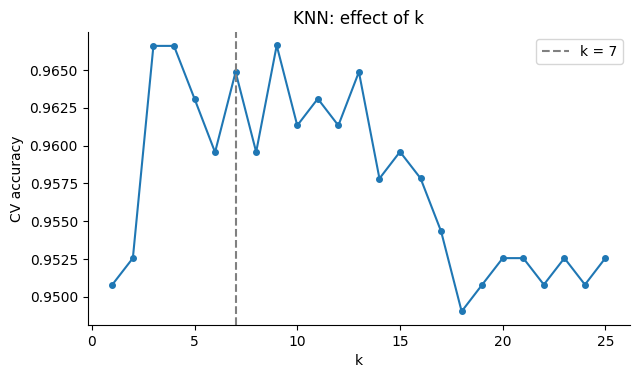

best k in this range: 9 with CV accuracy 0.9666


In [31]:
ks = range(1, 26)
k_scores = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                            X_clf, y_clf, cv=skf, scoring="accuracy").mean() for k in ks]

plt.figure(figsize=(7, 3.8))
plt.plot(list(ks), k_scores, marker="o", ms=4)
plt.axvline(7, color="gray", ls="--", label="k = 7")
plt.xlabel("k"); plt.ylabel("CV accuracy"); plt.legend(); plt.title("KNN: effect of k")
plt.show()
print("best k in this range:", list(ks)[int(np.argmax(k_scores))], "with CV accuracy", round(max(k_scores), 4))

### What is the Random Forest looking at?

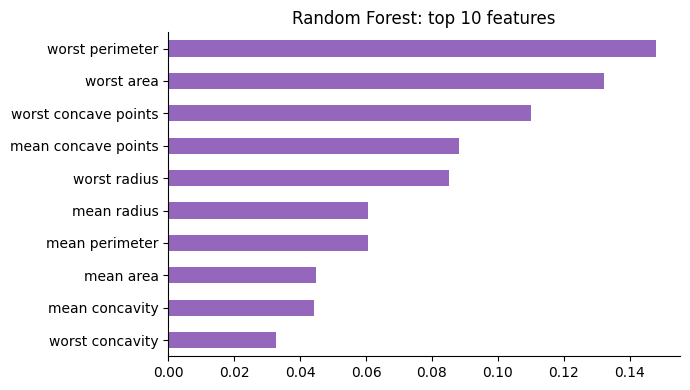

In [32]:
rf = sk_clf["Random Forest (sklearn)"]
imp = pd.Series(rf.feature_importances_, index=X_clf.columns).sort_values().tail(10)
plt.figure(figsize=(7, 4))
imp.plot.barh(color="tab:purple")
plt.title("Random Forest: top 10 features")
plt.tight_layout(); plt.show()

### What I take from Part 2

- **Logistic Regression came out on top**, both on the test split (my scratch version: 97.4% accuracy, 95.2% recall, F1 0.964) and in cross-validation (scikit-learn version: 97.4% accuracy, 94.4% recall, F1 0.963). The two versions disagree on a single test prediction. My guess is that's down to scikit-learn applying L2 regularisation by default and mine having none, but I didn't test that.
- **KNN and Decision Tree match scikit-learn exactly** (0 differing predictions), and **Naive Bayes matches once I add the same variance padding** scikit-learn uses (see the check above).
- **Random Forest** had perfect precision on the test set (never raised a false alarm), but recall of 90.5%, meaning it missed 4 of the 42 malignant tumours. For this problem I'd take a model that catches more of them over one that never cries wolf.
- **Naive Bayes** is the clearest example of why accuracy isn't enough. The scikit-learn version also had 100% precision but only 83.3% recall, so it missed 7 of 42 malignant tumours.
- **A single tree is the least reliable**: last in cross-validation (91.7% accuracy) with the widest spread between folds (std 0.031). The Random Forest, which is just many trees averaged, gains about 3.7 points over it (95.4%) and has the steadiest scores of all (std 0.010).
- **KNN's k=7** was a reasonable pick. Cross-validated accuracy is flat in that region, and the best k in the range I tried (k=9) is only slightly higher (96.7% vs 96.5%).
- The Random Forest leans mostly on size and shape measurements: worst perimeter, worst area and the concave-points features. That fits what I'd expect, since malignant tumours tend to be larger with more irregular outlines.

---
## Final summary

**What I trained:** 5 regression models and 9 classification models. For Linear Regression, Logistic Regression, KNN, Decision Tree and Naive Bayes I trained both a from-scratch version and a scikit-learn version, and Random Forest only with scikit-learn.

| | Best model | Key numbers |
|---|---|---|
| Regression (Diabetes) | Linear Regression | CV R² 0.482, test R² 0.453, test RMSE 53.9 |
| Classification (Breast Cancer) | Logistic Regression | CV accuracy 97.4%, CV recall 94.4%, CV F1 0.963 |

**On scratch vs library:** the from-scratch models behave like their scikit-learn counterparts. Linear Regression, KNN and the Decision Tree match almost perfectly, and the Naive Bayes gap is fully explained by one numerical detail. The library versions are still far more convenient. Scratch KNN is fine at this size, but the scratch Decision Tree took about 2 seconds to train a depth-3 tree that scikit-learn builds in milliseconds.

**Things to keep in mind:**
- Both datasets are small, so a single train/test split is noisy. That's why I also ran cross-validation, and in regression it actually changed which model looked best.
- I did very little hyperparameter tuning (tree depth, k and forest size were picked by hand, apart from the quick check on k). A proper `GridSearchCV` could shift the rankings a bit, especially for Random Forest.
- For the cancer data, recall matters more than accuracy. Lowering the decision threshold on a probability model such as Logistic Regression would trade a few extra false alarms for fewer missed tumours.

**If I had more time:** try Ridge/Lasso on the regression problem, tune the Random Forest with GridSearchCV, and write a from-scratch Random Forest on top of my Decision Tree class.